# v2 — Notebook 11 · Clustering countries by trade behaviour (Objective 4)

v1 clustered *day-types*; v2 clusters *countries*. We summarise each country by five interpretable
features and group similar trading nations with K-means. This answers "which countries behave alike?"
— big surplus exporters vs small deficit economies vs fast-growing newcomers.

Features: **size** (log avg total trade), **balance_ratio** (surplus + / deficit −), **growth**
(annual log trend), **seasonality** (STL seasonal strength), **volatility** (month-to-month).
Logic in `src/clustering.py`.
> ⚠️ v2 = international trade.

## Step 0 · Setup + features

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
def find_v2_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "src" / "clustering.py").exists():
            return base
    raise FileNotFoundError("v2 root not found")
V2 = find_v2_root(); sys.path.insert(0, str(V2))
DATA = V2.parent / "data" / "eu_trade_monthly.csv"

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110
from src import preprocess as pp, clustering as cl

df = pp.load_trade(DATA)
feats = cl.country_features(df)
print("features:", feats.shape)
feats.round(2)

features: (27, 5)


,size_log,balance_ratio,growth,seasonality,volatility
AT,10.07,-0.02,0.04,0.71,0.12
BE,11.00,0.02,0.03,0.62,0.10
BG,8.37,-0.09,0.08,0.52,0.09
CY,6.71,-0.52,0.10,0.24,0.32
CZ,10.00,0.04,0.07,0.60,0.12
DE,12.06,0.09,0.04,0.55,0.09
DK,9.55,0.05,0.03,0.57,0.09
EE,7.67,-0.08,0.07,0.48,0.10
EL,8.87,-0.33,0.06,0.57,0.13
ES,10.73,-0.09,0.05,0.70,0.14


## Step 1 · How many clusters? (silhouette)

**What:** silhouette score for several k. **Why:** pick k where countries separate best. **How to
read:** higher = better-separated; we use the best k below.

2    0.520
3    0.265
4    0.261
5    0.262
6    0.242
silhouette-best k = 2
Note: k=2 simply isolates the tiny island economies (Cyprus, Malta) as outliers,
giving one big blob. For interpretable groups we use k=4 below.


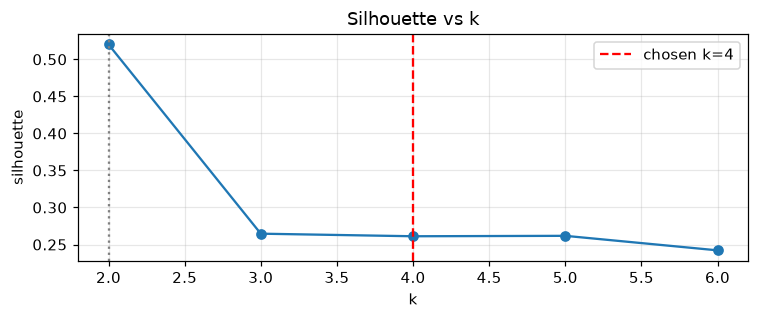

In [2]:
sk = cl.best_k(feats, ks=range(2, 7))
print(sk.round(3).to_string())
print("silhouette-best k =", int(sk.idxmax()))
print("Note: k=2 simply isolates the tiny island economies (Cyprus, Malta) as outliers,")
print("giving one big blob. For interpretable groups we use k=4 below.")
k = 4
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(sk.index, sk.values, "o-"); ax.axvline(int(sk.idxmax()), color="grey", ls=":")
ax.axvline(k, color="red", ls="--", label=f"chosen k={k}")
ax.set_title("Silhouette vs k"); ax.set_xlabel("k"); ax.set_ylabel("silhouette"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Step 2 · Cluster the countries

**How to read:** each country gets a group label; members listed per cluster.

In [3]:
labels = cl.cluster_countries(feats, k=k)
members = cl.cluster_members(labels)
for cid, ccs in members.items():
    print(f"Cluster {cid}: {', '.join(ccs)}")

Cluster 0: BG, CZ, EE, LT, LV, PL, RO, SI, SK
Cluster 1: AT, BE, DE, DK, ES, FI, FR, HU, IE, IT, NL, PT, SE
Cluster 2: CY
Cluster 3: EL, HR, LU, MT


## Step 3 · What does each cluster mean? (profiles)

**How to read:** the mean features per cluster name the group — e.g. large surplus exporters vs
small fast-growers.

In [4]:
prof = cl.cluster_profiles(feats, labels)
print(prof.round(2).to_string())

         size_log  balance_ratio  growth  seasonality  volatility
cluster                                                          
0            8.83          -0.05    0.08         0.55        0.10
1           10.38           0.01    0.04         0.60        0.12
2            6.71          -0.52    0.10         0.24        0.32
3            7.83          -0.27    0.04         0.49        0.15


## Step 4 · Visualise — size vs balance, coloured by cluster

**How to read:** x = economic size, y = surplus/deficit tendency; colours = clusters. Germany/
Netherlands sit top-right (big surplus); deficit economies sit below zero.

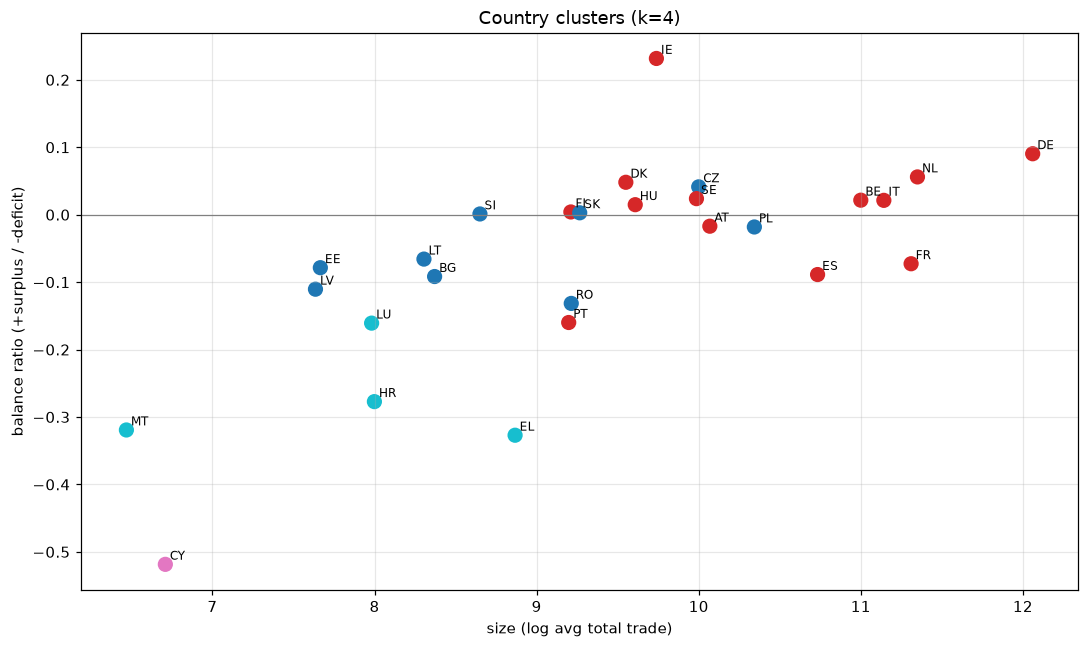

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(feats["size_log"], feats["balance_ratio"], c=labels, cmap="tab10", s=80)
for cc in feats.index:
    ax.annotate(cc, (feats.loc[cc, "size_log"], feats.loc[cc, "balance_ratio"]), fontsize=8,
                xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="grey", lw=.8)
ax.set_xlabel("size (log avg total trade)"); ax.set_ylabel("balance ratio (+surplus / -deficit)")
ax.set_title(f"Country clusters (k={k})"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Step 5 · Summary

| Feature | Meaning |
| --- | --- |
| size_log | economic size (log average total trade) |
| balance_ratio | surplus (+) vs deficit (−), scale-free |
| growth | annual log-trend of exports |
| seasonality | STL seasonal strength |
| volatility | month-to-month log volatility |

K-means groups the 27 countries into interpretable trade types (large surplus exporters, deficit
economies, fast-growing newcomers, small/volatile traders). This satisfies **Objective 4** and feeds
the reasoning layer ("country X behaves like its cluster peers").

**→ Next: deep model (multivariate autoencoder), web UI, final report.**